# Dữ liệu và tiền xử lý
UCI Appliances ghi điện năng thiết bị của một ngôi nhà. Mục tiêu là Wh trong sáu khoảng 10 phút tiếp theo. Không suy ra công suất đỉnh hoặc tiết kiệm thực tế từ các số đo này.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'appliances_core.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import appliances_core as v1
from v2 import core


In [2]:
df, audit = v1.load_raw(ROOT/'data/energydata_complete.csv')
display(pd.DataFrame([audit]))
display(df.head())

,rows,start,end,was_sorted,sha256,missing_cells,grid_gaps,duplicates,appliances_multiple_of_10,rv1_equals_rv2
0,19735,2016-01-11 17:00:00,2016-05-27 18:00:00,True,2820bf712ad0275cb18b85a05250926100d8e65ebb9f4d...,0,0,0,True,True


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,t
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,2016-01-11 17:00:00
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,2016-01-11 17:10:00
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,2016-01-11 17:20:00
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,2016-01-11 17:30:00
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,2016-01-11 17:40:00


## Vì sao giữ đỉnh và chia theo thời gian
CSV gốc không có ô thiếu hoặc khoảng trống trên lưới 10 phút. Giữ các đỉnh hợp lệ để đánh giá nhóm cao. Scaler chỉ học TRAIN; không xáo trộn chuỗi hoặc dùng SMOTE cho hồi quy này.

In [3]:
X, Y = core.build_features(df), v1.build_labels(df)
display(X[core.FEATURE_SETS['F']].iloc[144:149])
display(pd.DataFrame({'ten': ['A', 'F'], 'so_dac_trung': [18, 22]}))

,app_lag_0,app_lag_1,app_lag_2,app_lag_3,app_lag_6,app_lag_144,app_yday_window_sum,app_sum_1h,app_max_1h,app_mean_3h,...,app_max_24h,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,app_diff_1,app_diff_3,app_std_1h,app_ratio_max1h_mean24h
144,60.0,40.0,40.0,40.0,30.0,60.0,330.0,270.0,60.0,71.111111,...,580.0,-0.976296,-0.216440,0.781831,0.62349,0.0,20.0,20.0,7.637626,0.570900
145,60.0,60.0,40.0,40.0,40.0,60.0,330.0,290.0,60.0,71.111111,...,580.0,-0.984808,-0.173648,0.781831,0.62349,0.0,0.0,20.0,8.975275,0.570900
146,210.0,60.0,60.0,40.0,50.0,50.0,340.0,450.0,210.0,79.444444,...,580.0,-0.991445,-0.130526,0.781831,0.62349,0.0,150.0,170.0,61.032778,1.977246
147,380.0,210.0,60.0,60.0,40.0,50.0,360.0,790.0,380.0,80.000000,...,580.0,-0.996195,-0.087156,0.781831,0.62349,0.0,170.0,320.0,125.753286,3.502304
148,370.0,380.0,210.0,60.0,40.0,60.0,530.0,1120.0,380.0,89.444444,...,580.0,-0.999048,-0.043619,0.781831,0.62349,0.0,-10.0,310.0,144.414527,3.434166


,ten,so_dac_trung
0,A,18
1,F,22


PASS: sửa tương lai không làm đổi đặc trưng tại t


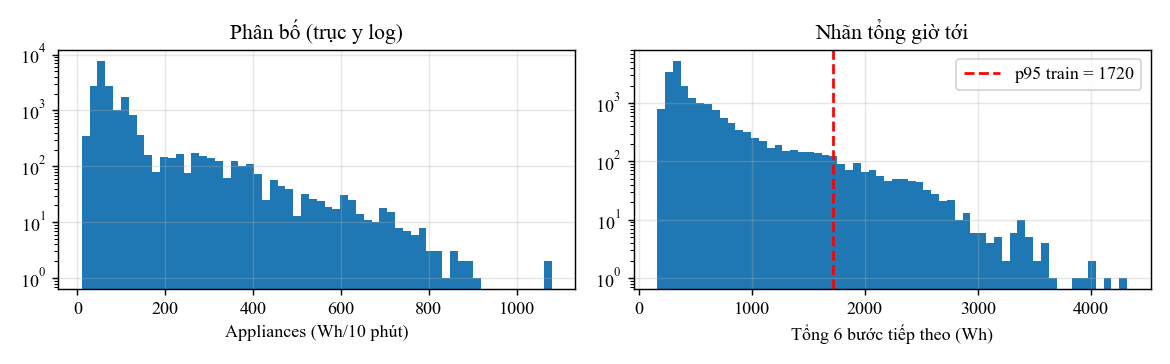

In [4]:
i = 5000
changed = df.copy()
changed.loc[i+1:, 'Appliances'] *= 9
np.testing.assert_array_equal(X.iloc[i].to_numpy(), core.build_features(changed).iloc[i].to_numpy())
print('PASS: sửa tương lai không làm đổi đặc trưng tại t')
display(Image(filename=str(ROOT/'out/figures/f32_distribution.png')))